
# Adaptive Visual Inspection System with RL-Based Inspection Scheduling

## Reinforcement Learning: Q-Learning-Based Inspection Scheduler

### Overview
This notebook implements a reinforcement learning-based scheduler that selects an appropriate inspection action for each product using precomputed Mahalanobis anomaly scores from the MVTec Anomaly Detection dataset.

The scheduler aims to balance inspection cost and defect detection by choosing between skipping further inspection, using the existing anomaly prediction, and requesting expert review.

### Objectives
- Load and inspect the existing Mahalanobis anomaly-score dataset.
- Prepare the data for reinforcement learning.
- Define the inspection environment, states, actions, and rewards.
- Train a Q-learning agent to learn an inspection policy.
- Evaluate the learned policy against baseline strategies.
- Generate structured outputs for downstream defect analysis and RAG integration.



In [48]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## 1. Configuration and Reproducibility

This section defines the dataset path, random seed, Q-learning parameters, and inspection cost settings. Centralizing these values makes the experiments easier to reproduce and modify.


In [49]:

# Import required libraries

import os
import random
import json
import numpy as np
import pandas as pd

# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Dataset configuration
DATA_PATH = "/content/drive/MyDrive/Integrated/outputs/vision/current_anomaly_score.csv"

# MVTec categories used in the project
CATEGORIES = [
    "grid",
    "zipper",
    "hazelnut",
    "leather",
    "toothbrush"
]

# Q-learning configuration
ALPHA = 0.1          # Learning rate
GAMMA = 0.9           # Discount factor
EPSILON = 0.2         # Initial exploration probability
EPISODES = 500        # Number of training episodes

# Illustrative inspection costs
SKIP_COST = 0
PREDICTION_COST = 1
EXPERT_COST = 5

# Illustrative penalties
MISSED_DEFECT_PENALTY = 10
FALSE_REJECTION_PENALTY = 3

print("Configuration initialized successfully.")
print("Random seed:", SEED)
print("Categories:", CATEGORIES)


Configuration initialized successfully.
Random seed: 42
Categories: ['grid', 'zipper', 'hazelnut', 'leather', 'toothbrush']



### Evaluation Integrity and Leakage Prevention

The Mahalanobis anomaly detector is treated as the fixed vision model for the RL scheduling experiment. The default anomaly threshold is derived from cross-validated scores of good training images using the 95th percentile.

The separate best-F1 threshold is excluded from the RL experiment because it is calculated using test labels and may produce optimistic results.

The RL dataset is split into training and held-out test subsets. The Q-table is trained only on the training subset, and the held-out test subset is used to evaluate the learned scheduling policy.

The vision notebook previously selected the best vision method using test-set AUC. Therefore, the current RL evaluation is a held-out scheduler evaluation conditional on the selected Mahalanobis model, not a completely independent end-to-end evaluation of the vision-plus-RL system.

All simulated inspection costs and the assumption of perfect expert review are illustrative and must not be interpreted as measured real-world costs or performance.



## 2. Load and Validate the Anomaly-Score Dataset

This section loads the anomaly-score CSV generated by the vision component. We inspect its structure, verify the required columns, check missing values, and examine the distribution of categories and labels before preparing the reinforcement learning environment.


In [50]:

# Load the anomaly-score dataset

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Please upload anomaly_scores.csv to Colab "
        "or update DATA_PATH to the correct file location."
    )

df = pd.read_csv(DATA_PATH)

# Display dataset dimensions
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

# Inspect column names
print("\nAvailable columns:")
print(df.columns.tolist())

# Display the first five rows
display(df.head())

# Check missing values
print("\nMissing values per column:")
display(df.isnull().sum())

# Inspect category distribution
if "category" in df.columns:
    print("\nCategory distribution:")
    display(df["category"].value_counts())

# Inspect label distribution
if "label" in df.columns:
    print("\nLabel distribution (0 = good, 1 = defective):")
    display(df["label"].value_counts())

# Inspect available detection methods
if "method" in df.columns:
    print("\nAvailable anomaly detection methods:")
    display(df["method"].value_counts())


Dataset loaded successfully.
Dataset shape: (1515, 11)

Available columns:
['category', 'image_path', 'true_defect_type', 'label', 'method', 'anomaly_score', 'threshold', 'prediction', 'predicted_defect_type', 'normalized_score', 'normalized_threshold']


,category,image_path,true_defect_type,label,method,anomaly_score,threshold,prediction,predicted_defect_type,normalized_score,normalized_threshold
0,grid,grid/test/bent/000.png,bent,1,knn_cosine,0.019307,0.042509,0,glue,0.428030,0.94697
1,grid,grid/test/bent/001.png,bent,1,knn_cosine,0.026969,0.042509,0,metal_contamination,0.670455,0.94697
2,grid,grid/test/bent/002.png,bent,1,knn_cosine,0.014195,0.042509,0,bent,0.204545,0.94697
3,grid,grid/test/bent/003.png,bent,1,knn_cosine,0.023449,0.042509,0,metal_contamination,0.534091,0.94697
4,grid,grid/test/bent/004.png,bent,1,knn_cosine,0.011938,0.042509,0,broken,0.128788,0.94697



Missing values per column:


,0
category,0
image_path,0
true_defect_type,0
label,0
method,0
anomaly_score,0
threshold,0
prediction,0
predicted_defect_type,0
normalized_score,0



Category distribution:


,count
category,
zipper,453
leather,372
hazelnut,330
grid,234
toothbrush,126



Label distribution (0 = good, 1 = defective):


,count
label,
1,1104
0,411



Available anomaly detection methods:


,count
method,
knn_cosine,505
mahalanobis,505
ocsvm,505


In [51]:

# Validate the columns required for RL scheduling
required_columns = [
    "category",
    "image_path",
    "label",
    "anomaly_score",
    "threshold",
    "prediction"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Confirm the default prediction and threshold columns
print("Required columns are present.")
print("Default threshold column: threshold")
print("Default prediction column: prediction")

# Check whether test-label-derived comparison columns exist
for col in ["threshold_f1thr", "prediction_f1thr"]:
    print(f"{col} exists:", col in df.columns)

# Preserve image identifiers for later evaluation
assert df["image_path"].notna().all(), \
    "Some image paths are missing."

print("Image paths are present for all records.")


Required columns are present.
Default threshold column: threshold
Default prediction column: prediction
threshold_f1thr exists: False
prediction_f1thr exists: False
Image paths are present for all records.



## 3. Filter and Inspect Mahalanobis Results

The original dataset contains predictions from three anomaly-detection methods. Since this RL component uses Mahalanobis only, we filter the dataset to retain its records.

We then verify the filtered dataset, inspect category-wise label distributions, and examine the normalized anomaly scores and thresholds before defining the RL state representation.


In [52]:

# Keep only Mahalanobis results
df_mahalanobis = df[
    df["method"].str.lower() == "mahalanobis"
].copy()

# Reset index for clean indexing
df_mahalanobis.reset_index(drop=True, inplace=True)

# Validate filtered dataset
print("Mahalanobis dataset shape:", df_mahalanobis.shape)
print("Unique methods:", df_mahalanobis["method"].unique())
print("Missing values:", df_mahalanobis.isnull().sum().sum())

# Verify category distribution
print("\nCategory distribution:")
display(df_mahalanobis["category"].value_counts().sort_index())

# Verify ground-truth label distribution
print("\nLabel distribution (0 = good, 1 = defective):")
display(df_mahalanobis["label"].value_counts().sort_index())

# Inspect labels by category
print("\nGround-truth labels by category:")
display(pd.crosstab(
    df_mahalanobis["category"],
    df_mahalanobis["label"],
    margins=True
))

# Inspect normalized anomaly scores
print("\nNormalized score statistics:")
display(df_mahalanobis["normalized_score"].describe())

# Inspect normalized thresholds by category
print("\nNormalized thresholds by category:")
display(
    df_mahalanobis.groupby("category")["normalized_threshold"]
    .agg(["min", "max", "mean", "std"])
    .round(4)
)

# Verify whether predictions agree with the stored threshold
threshold_check = (
    df_mahalanobis["normalized_score"]
    >= df_mahalanobis["normalized_threshold"]
)

print(
    "\nRows where score >= normalized threshold:",
    int(threshold_check.sum())
)
print(
    "Rows predicted defective:",
    int((df_mahalanobis["prediction"] == 1).sum())
)


Mahalanobis dataset shape: (505, 11)
Unique methods: ['mahalanobis']
Missing values: 0

Category distribution:


,count
category,
grid,78
hazelnut,110
leather,124
toothbrush,42
zipper,151



Label distribution (0 = good, 1 = defective):


,count
label,
0,137
1,368



Ground-truth labels by category:


...


Normalized score statistics:


,normalized_score
count,505.000000
mean,0.857680
std,0.232474
min,0.035806
25%,0.818182
50%,0.987500
75%,1.000000
max,1.000000



Normalized thresholds by category:


,min,max,mean,std
category,,,,
grid,0.9470,0.9470,0.9470,0.0
hazelnut,0.9488,0.9488,0.9488,0.0
leather,0.9469,0.9469,0.9469,0.0
toothbrush,0.9500,0.9500,0.9500,0.0
zipper,0.9500,0.9500,0.9500,0.0



Rows where score >= normalized threshold: 306
Rows predicted defective: 306



## 4. Define Risk Levels and RL States

The RL agent observes the product category and the severity of its anomaly score relative to the category-specific detection threshold.

Three risk levels are defined:
- Low risk: the score is sufficiently below the threshold.
- Medium risk: the score is close to the threshold.
- High risk: the score is sufficiently above the threshold.

These boundaries are heuristic and will be validated against the observed score distribution. The ground-truth label is retained for reward calculation and evaluation, but it must not be used as an input to the agent's state.


In [53]:

# Define the margin around the category-specific threshold
RISK_MARGIN = 0.10

# Calculate the difference between normalized score and threshold
df_mahalanobis["threshold_margin"] = (
    df_mahalanobis["normalized_score"]
    - df_mahalanobis["normalized_threshold"]
)

# Assign risk levels consistently with the project definition
def assign_risk_level(margin):
    if margin < -RISK_MARGIN:
        return "low"
    elif margin < 0:
        return "medium"
    else:
        return "high"

df_mahalanobis["risk_level"] = (
    df_mahalanobis["threshold_margin"].apply(assign_risk_level)
)

# Create the RL state from category and risk level
df_mahalanobis["state"] = list(zip(
    df_mahalanobis["category"],
    df_mahalanobis["risk_level"]
))

# Inspect risk distribution
print("Risk-level distribution:")
display(
    df_mahalanobis["risk_level"]
    .value_counts()
    .reindex(["low", "medium", "high"], fill_value=0)
)

print("\nRisk levels by category:")
display(pd.crosstab(
    df_mahalanobis["category"],
    df_mahalanobis["risk_level"],
    margins=True
))

print("\nNumber of observed states:",
      df_mahalanobis["state"].nunique())

# Ensure image identifiers remain available
assert df_mahalanobis["image_path"].notna().all()


Risk-level distribution:


,count
risk_level,
low,141
medium,58
high,306



Risk levels by category:


risk_level,high,low,medium,All
category,,,,
grid,13,44,21,78
hazelnut,61,38,11,110
leather,105,8,11,124
toothbrush,24,16,2,42
zipper,103,35,13,151
All,306,141,58,505



Number of observed states: 15



## 5. Define Inspection Actions and Reward Function

The inspection scheduler selects one of three actions for each product:

1. **Skip:** Skip further inspection and allow the product to proceed.
2. **Prediction:** Use the existing Mahalanobis prediction to flag suspected defects or pass the product.
3. **Expert Review:** Request expert inspection. For this offline prototype, the expert is simulated as perfectly identifying defective and good products.

The reward function accounts for inspection cost, missed defects, and false rejections. Ground-truth labels are used only to simulate outcomes and calculate rewards during offline training and evaluation; they are not part of the agent's state.


In [54]:

# Define the available inspection actions
ACTIONS = ["skip", "prediction", "expert"]

# Define illustrative action costs
ACTION_COSTS = {
    "skip": SKIP_COST,
    "prediction": PREDICTION_COST,
    "expert": EXPERT_COST
}

# Define the reward function
def calculate_reward(row, action):
    """
    Calculate reward for an inspection action.

    Ground-truth labels are used only to simulate the
    outcome and calculate the reward in this offline prototype.
    """

    label = int(row["label"])
    prediction = int(row["prediction"])

    # Start with the action's inspection cost
    reward = -ACTION_COSTS[action]

    # Simulate the outcome of the selected action
    if action == "skip":
        # Product proceeds without further inspection
        missed_defect = (label == 1)
        false_rejection = False

    elif action == "prediction":
        # Use the existing Mahalanobis prediction
        missed_defect = (label == 1 and prediction == 0)
        false_rejection = (label == 0 and prediction == 1)

    elif action == "expert":
        # Assume perfect expert review in this simulation
        missed_defect = False
        false_rejection = False

    else:
        raise ValueError(f"Unknown action: {action}")

    # Apply penalties for inspection errors
    if missed_defect:
        reward -= MISSED_DEFECT_PENALTY

    if false_rejection:
        reward -= FALSE_REJECTION_PENALTY

    return reward


# Inspect action costs and reward settings
print("Available actions:", ACTIONS)
print("\nAction costs:")
display(pd.Series(ACTION_COSTS, name="cost"))

print("\nPenalty settings:")
print("Missed-defect penalty:", MISSED_DEFECT_PENALTY)
print("False-rejection penalty:", FALSE_REJECTION_PENALTY)

# Test the reward function on one sample row
sample_row = df_mahalanobis.iloc[0]

print("\nSample product:")
print("Category:", sample_row["category"])
print("Ground-truth label:", sample_row["label"])
print("Mahalanobis prediction:", sample_row["prediction"])

print("\nRewards for each action:")
for action in ACTIONS:
    print(action, "->", calculate_reward(sample_row, action))


Available actions: ['skip', 'prediction', 'expert']

Action costs:


,cost
skip,0
prediction,1
expert,5



Penalty settings:
Missed-defect penalty: 10
False-rejection penalty: 3

Sample product:
Category: grid
Ground-truth label: 1
Mahalanobis prediction: 0

Rewards for each action:
skip -> -10
prediction -> -11
expert -> -5



## 6. Implement the Q-Learning Agent

### 6.1 Initialize the Q-Table

The Q-table represents the expected value of selecting each inspection action for a given state. Each state consists of a product category and its anomaly risk level.

The agent uses an epsilon-greedy strategy to balance exploration (trying different actions) and exploitation (choosing the action with the highest learned Q-value).

Initially, all Q-values are set to zero. They are updated using observed rewards during training.


In [55]:

# Create the list of unique states
STATES = sorted(df_mahalanobis["state"].unique())

# Map states and actions to numerical indices
STATE_TO_INDEX = {
    state: index for index, state in enumerate(STATES)
}

ACTION_TO_INDEX = {
    action: index for index, action in enumerate(ACTIONS)
}

INDEX_TO_ACTION = {
    index: action for action, index in ACTION_TO_INDEX.items()
}

# Initialize the Q-table with zeros
Q_TABLE = np.zeros((len(STATES), len(ACTIONS)))

print("Q-table initialized successfully.")
print("Number of states:", len(STATES))
print("Number of actions:", len(ACTIONS))
print("Q-table shape:", Q_TABLE.shape)

# Display the initial Q-table
q_table_df = pd.DataFrame(
    Q_TABLE,
    index=[str(state) for state in STATES],
    columns=ACTIONS
)

display(q_table_df)


Q-table initialized successfully.
Number of states: 15
Number of actions: 3
Q-table shape: (15, 3)


,skip,prediction,expert
"('grid', 'high')",0.0,0.0,0.0
"('grid', 'low')",0.0,0.0,0.0
"('grid', 'medium')",0.0,0.0,0.0
"('hazelnut', 'high')",0.0,0.0,0.0
"('hazelnut', 'low')",0.0,0.0,0.0
"('hazelnut', 'medium')",0.0,0.0,0.0
"('leather', 'high')",0.0,0.0,0.0
"('leather', 'low')",0.0,0.0,0.0
"('leather', 'medium')",0.0,0.0,0.0
"('toothbrush', 'high')",0.0,0.0,0.0



### 6.2 Epsilon-Greedy Action Selection

The epsilon-greedy strategy controls how the agent chooses actions.

- With probability epsilon, the agent explores by choosing a random action.
- Otherwise, the agent exploits its current knowledge by choosing an action with the highest Q-value.

This allows the agent to explore different inspection strategies before relying more heavily on the actions that have produced better rewards.


In [56]:

# Select an action using the epsilon-greedy strategy
def choose_action(state, epsilon=EPSILON):
    state_index = STATE_TO_INDEX[state]

    # Explore: choose a random action
    if np.random.random() < epsilon:
        action_index = np.random.randint(len(ACTIONS))

    # Exploit: choose the action with the highest Q-value
    else:
        q_values = Q_TABLE[state_index]

        # Randomly break ties between equally valued actions
        best_actions = np.flatnonzero(
            q_values == q_values.max()
        )
        action_index = np.random.choice(best_actions)

    return INDEX_TO_ACTION[action_index]


# Test action selection
sample_state = STATES[0]

print("Sample state:", sample_state)
print("Selected action:", choose_action(sample_state))


Sample state: ('grid', 'high')
Selected action: skip



### 6.3 Q-Learning Update Rule

After an action is taken, the agent receives a reward. The Q-value is updated using the difference between its current estimate and the new target value.

For non-terminal transitions, the target includes the maximum Q-value of the next state. For terminal transitions, no future reward is assumed.


In [57]:

# Update the Q-value for a state-action pair
def update_q_value(state, action, reward, next_state=None):
    state_index = STATE_TO_INDEX[state]
    action_index = ACTION_TO_INDEX[action]

    current_q = Q_TABLE[state_index, action_index]

    # No future value is added after a terminal transition
    if next_state is None:
        next_max_q = 0.0
    else:
        next_state_index = STATE_TO_INDEX[next_state]
        next_max_q = np.max(Q_TABLE[next_state_index])

    # Calculate the Q-learning target
    target = reward + GAMMA * next_max_q

    # Apply the Q-learning update
    Q_TABLE[state_index, action_index] = (
        current_q + ALPHA * (target - current_q)
    )

    return Q_TABLE[state_index, action_index]


print("Q-learning update function defined successfully.")


Q-learning update function defined successfully.


Testing

In [58]:

# Test one learning update using a real dataset row
test_row = df_mahalanobis.iloc[0]

test_state = test_row["state"]
test_action = "prediction"
test_reward = calculate_reward(test_row, test_action)

old_q_value = Q_TABLE[
    STATE_TO_INDEX[test_state],
    ACTION_TO_INDEX[test_action]
]

new_q_value = update_q_value(
    state=test_state,
    action=test_action,
    reward=test_reward,
    next_state=None
)

print("Test state:", test_state)
print("Test action:", test_action)
print("Observed reward:", test_reward)
print("Q-value before update:", round(old_q_value, 4))
print("Q-value after update:", round(new_q_value, 4))

assert np.isclose(
    new_q_value,
    old_q_value + ALPHA * (test_reward - old_q_value)
)

print("\nQ-learning update test passed.")


Test state: ('grid', 'low')
Test action: prediction
Observed reward: -11
Q-value before update: 0.0
Q-value after update: -1.1

Q-learning update test passed.



### 6.4 Train the Q-Learning Agent

The agent is trained using the Mahalanobis dataset. During each episode, the records are shuffled, the agent selects an inspection action using an epsilon-greedy policy, and the reward function evaluates the simulated outcome.

The Q-table is updated after each action. Exploration gradually decreases so the agent initially tries different actions and later increasingly uses its learned action values.

Each image remains identifiable through its original image path. Since the current cases are independent, each update is treated as a terminal transition.


In [59]:
# Reset the Q-table before full training
Q_TABLE = np.zeros((len(STATES), len(ACTIONS)))

# Training configuration
MIN_EPSILON = 0.05
EPSILON_DECAY = 0.995

# Store training statistics
training_rewards = []
training_action_counts = []

print("Starting Q-learning training...")

for episode in range(EPISODES):

    # Gradually reduce exploration
    current_epsilon = max(
        MIN_EPSILON,
        EPSILON * (EPSILON_DECAY ** episode)
    )

    # Shuffle the independent inspection records
    shuffled_data = df_mahalanobis.sample(
        frac=1,
        random_state=SEED + episode
    )

    episode_reward = 0
    action_counts = {action: 0 for action in ACTIONS}

    for _, row in shuffled_data.iterrows():

        # Preserve image identity for traceability
        image_path = row["image_path"]

        # Select the observable RL state
        state = row["state"]

        # Choose an action using epsilon-greedy selection
        action = choose_action(
            state,
            epsilon=current_epsilon
        )

        # Simulate the outcome and calculate reward
        reward = calculate_reward(row, action)

        # Independent image: use a terminal update
        update_q_value(
            state=state,
            action=action,
            reward=reward,
            next_state=None
        )

        # Track episode statistics
        episode_reward += reward
        action_counts[action] += 1

    training_rewards.append(episode_reward)
    training_action_counts.append(action_counts)

    if (episode + 1) % 50 == 0:
        print(
            f"Episode {episode + 1}/{EPISODES} | "
            f"Reward: {episode_reward} | "
            f"Epsilon: {current_epsilon:.4f}"
        )

print("\nTraining completed successfully.")
print("Total episodes:", EPISODES)
print("Q-table shape:", Q_TABLE.shape)
print("Records per episode:", len(df_mahalanobis))

# Display final learned Q-values
q_table_df = pd.DataFrame(
    Q_TABLE,
    index=[str(state) for state in STATES],
    columns=ACTIONS
)

print("\nLearned Q-table:")
display(q_table_df.round(3))

# Summarize action selections in the final episode
print("\nAction counts in the final training episode:")
display(pd.Series(training_action_counts[-1], name="count"))

# Inspect image-path availability for traceability
print("\nImage path retained in training data:",
      "image_path" in df_mahalanobis.columns)
print("Example image path:",
      df_mahalanobis.iloc[0]["image_path"])


Starting Q-learning training...
Episode 50/500 | Reward: -1220 | Epsilon: 0.1564
Episode 100/500 | Reward: -1201 | Epsilon: 0.1218
Episode 150/500 | Reward: -1152 | Epsilon: 0.0948
Episode 200/500 | Reward: -1194 | Epsilon: 0.0738
Episode 250/500 | Reward: -1106 | Epsilon: 0.0574
Episode 300/500 | Reward: -1069 | Epsilon: 0.0500
Episode 350/500 | Reward: -1073 | Epsilon: 0.0500
Episode 400/500 | Reward: -1057 | Epsilon: 0.0500
Episode 450/500 | Reward: -1181 | Epsilon: 0.0500
Episode 500/500 | Reward: -1103 | Epsilon: 0.0500

Training completed successfully.
Total episodes: 500
Q-table shape: (15, 3)
Records per episode: 505

Learned Q-table:


,skip,prediction,expert
"('grid', 'high')",-8.623,-1.856,-5.0
"('grid', 'low')",-5.916,-6.583,-5.0
"('grid', 'medium')",-7.406,-7.269,-5.0
"('hazelnut', 'high')",-9.994,-1.024,-5.0
"('hazelnut', 'low')",-0.491,-2.561,-5.0
"('hazelnut', 'medium')",-5.653,-6.375,-5.0
"('leather', 'high')",-9.433,-1.072,-5.0
"('leather', 'low')",0.000,-1.000,-5.0
"('leather', 'medium')",-0.857,-5.640,-5.0
"('toothbrush', 'high')",-10.000,-1.000,-5.0



Action counts in the final training episode:


,count
skip,111
prediction,295
expert,99



Image path retained in training data: True
Example image path: grid/test/bent/000.png



## 7. Evaluate the Inspection Scheduling Policy

### 7.1 Baseline Strategies and Evaluation Metrics

The learned Q-policy is compared against three baseline strategies: always skip further inspection, always use the existing Mahalanobis prediction, and always request expert review.

Evaluation considers defect recall, missed-defect rate, false-rejection rate, expert-review rate, and simulated cost per image.

The current Q-table was trained on all 505 records. Results on these same records are therefore descriptive training-data results, not independent test performance. A separate held-out evaluation will be required for a stronger performance claim.


In [60]:

# Define baseline and learned policies

def always_skip(row):
    return "skip"

def always_prediction(row):
    return "prediction"

def always_expert(row):
    return "expert"

def learned_q_policy(row):
    state_index = STATE_TO_INDEX[row["state"]]

    # Select the action with the highest learned Q-value
    action_index = int(np.argmax(Q_TABLE[state_index]))

    return INDEX_TO_ACTION[action_index]


POLICIES = {
    "Always Skip": always_skip,
    "Always Prediction": always_prediction,
    "Always Expert": always_expert,
    "Learned Q-Policy": learned_q_policy
}

print("Policies prepared:")
for policy_name in POLICIES:
    print("-", policy_name)


Policies prepared:
- Always Skip
- Always Prediction
- Always Expert
- Learned Q-Policy


In [61]:

# Evaluate one policy on the Mahalanobis records

def evaluate_policy(data, policy_function):
    results = []

    for _, row in data.iterrows():
        action = policy_function(row)

        label = int(row["label"])
        prediction = int(row["prediction"])

        # Simulate the final inspection decision:
        # 0 = product passes, 1 = product is rejected/flagged
        if action == "skip":
            final_decision = 0

        elif action == "prediction":
            final_decision = prediction

        elif action == "expert":
            # Offline simulation assumes a perfect expert
            final_decision = label

        else:
            raise ValueError(f"Unknown action: {action}")

        # Error counts
        missed_defect = int(label == 1 and final_decision == 0)
        false_rejection = int(label == 0 and final_decision == 1)

        # Reward and simulated total cost
        reward = calculate_reward(row, action)
        # Calculate full simulated cost explicitly
        simulated_cost = ACTION_COSTS[action]

        if missed_defect:
            simulated_cost += MISSED_DEFECT_PENALTY

        if false_rejection:
            simulated_cost += FALSE_REJECTION_PENALTY

        results.append({
            "image_path": row["image_path"],
            "category": row["category"],
            "risk_level": row["risk_level"],
            "state": row["state"],
            "label": label,
            "mahalanobis_prediction": prediction,
            "selected_action": action,
            "final_decision": final_decision,
            "missed_defect": missed_defect,
            "false_rejection": false_rejection,
            "reward": reward,
            "simulated_cost": simulated_cost
        })

    results_df = pd.DataFrame(results)

    total_defects = int((results_df["label"] == 1).sum())
    total_good = int((results_df["label"] == 0).sum())

    missed_count = int(results_df["missed_defect"].sum())
    false_rejection_count = int(
        results_df["false_rejection"].sum()
    )

    detected_defects = total_defects - missed_count

    metrics = {
        "defect_recall": (
            detected_defects / total_defects
            if total_defects else 0
        ),
        "missed_defect_rate": (
            missed_count / total_defects
            if total_defects else 0
        ),
        "false_rejection_rate": (
            false_rejection_count / total_good
            if total_good else 0
        ),
        "expert_review_rate": (
            (results_df["selected_action"] == "expert").mean()
        ),
        "average_simulated_cost": (
            results_df["simulated_cost"].mean()
        ),
        "total_simulated_cost": (
            results_df["simulated_cost"].sum()
        ),
        "missed_defect_count": missed_count,
        "false_rejection_count": false_rejection_count
    }

    return results_df, metrics


print("Evaluation function defined successfully.")


Evaluation function defined successfully.


In [62]:

# Evaluate all policies on the current dataset
# NOTE: This is descriptive evaluation on training data.

policy_results = {}
comparison_rows = []

for policy_name, policy_function in POLICIES.items():

    results_df, metrics = evaluate_policy(
        df_mahalanobis,
        policy_function
    )

    policy_results[policy_name] = results_df

    comparison_rows.append({
        "policy": policy_name,
        **metrics
    })

comparison_df = pd.DataFrame(comparison_rows)

# Format rate metrics as percentages for readability
rate_columns = [
    "defect_recall",
    "missed_defect_rate",
    "false_rejection_rate",
    "expert_review_rate"
]

comparison_display = comparison_df.copy()

for column in rate_columns:
    comparison_display[column] = (
        comparison_display[column] * 100
    ).round(2)

comparison_display["average_simulated_cost"] = (
    comparison_display["average_simulated_cost"].round(3)
)

print("Policy comparison on the 505 records")
print("Rates are percentages; cost values are illustrative units.")
display(comparison_display)

# Inspect individual image-level decisions for the learned policy
print("\nSample learned-policy decisions:")
display(
    policy_results["Learned Q-Policy"][
        [
            "image_path",
            "category",
            "risk_level",
            "selected_action",
            "label",
            "final_decision",
            "reward",
            "simulated_cost"
        ]
    ].head(10)
)

# Verify that image paths were preserved for every policy
for policy_name, results_df in policy_results.items():
    assert len(results_df) == len(df_mahalanobis)
    assert results_df["image_path"].notna().all()

print("\nAll policies evaluated.")
print("Image-path traceability verified for all policies.")


Policy comparison on the 505 records
Rates are percentages; cost values are illustrative units.


,policy,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,total_simulated_cost,missed_defect_count,false_rejection_count
0,Always Skip,0.00,100.00,0.00,0.00,7.287,3680,368,0
1,Always Prediction,77.45,22.55,15.33,0.00,2.768,1398,83,21
2,Always Expert,100.00,0.00,0.00,100.00,5.000,2525,0,0
3,Learned Q-Policy,95.11,4.89,15.33,18.02,2.057,1039,18,21



Sample learned-policy decisions:


,image_path,category,risk_level,selected_action,label,final_decision,reward,simulated_cost
0,grid/test/bent/000.png,grid,low,expert,1,1,-5,5
1,grid/test/bent/001.png,grid,low,expert,1,1,-5,5
2,grid/test/bent/002.png,grid,low,expert,1,1,-5,5
3,grid/test/bent/003.png,grid,low,expert,1,1,-5,5
4,grid/test/bent/004.png,grid,low,expert,1,1,-5,5
5,grid/test/bent/005.png,grid,low,expert,1,1,-5,5
6,grid/test/bent/006.png,grid,medium,expert,1,1,-5,5
7,grid/test/bent/007.png,grid,low,expert,1,1,-5,5
8,grid/test/bent/008.png,grid,low,expert,1,1,-5,5
9,grid/test/bent/009.png,grid,low,expert,1,1,-5,5



All policies evaluated.
Image-path traceability verified for all policies.



## 8. Held-Out Evaluation

### 8.1 Split the Dataset

The Mahalanobis dataset is split into training and test subsets. The training subset is used to learn a fresh Q-table, while the test subset is reserved for evaluating the learned policy.

Stratification by category and ground-truth label helps preserve the distribution of good and defective products within each category.

The ground-truth label is used for stratification and offline reward calculation, but it is not provided to the policy when it selects an action.


In [63]:

from sklearn.model_selection import train_test_split

# Create a stratification key to preserve category-label proportions
stratify_key = (
    df_mahalanobis["category"].astype(str)
    + "_"
    + df_mahalanobis["label"].astype(str)
)

# Split into 80% training and 20% test data
train_df, test_df = train_test_split(
    df_mahalanobis,
    test_size=0.20,
    random_state=SEED,
    stratify=stratify_key
)

# Reset row indices
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training records:", len(train_df))
print("Test records:", len(test_df))

print("\nTraining label distribution:")
display(pd.crosstab(train_df["category"], train_df["label"]))

print("\nTest label distribution:")
display(pd.crosstab(test_df["category"], test_df["label"]))

# Verify there is no image-path overlap between the sets
train_paths = set(train_df["image_path"])
test_paths = set(test_df["image_path"])

print("\nOverlapping image paths:", len(train_paths & test_paths))

assert len(train_paths & test_paths) == 0
assert len(train_df) + len(test_df) == len(df_mahalanobis)

print("Train/test split validated.")


Training records: 404
Test records: 101

Training label distribution:


label,0,1
category,,
grid,17,46
hazelnut,32,56
leather,26,73
toothbrush,9,24
zipper,26,95



Test label distribution:


label,0,1
category,,
grid,4,11
hazelnut,8,14
leather,6,19
toothbrush,3,6
zipper,6,24



Overlapping image paths: 0
Train/test split validated.



### 8.2 Train the Policy on the Training Subset

A new Q-table is initialized from zero. The agent learns from training records only, using the existing action costs, reward function, and epsilon-greedy strategy.

Each record is treated as an independent terminal case. The test subset is not used during training.


In [64]:

# Initialize a fresh Q-table for held-out evaluation
Q_TABLE = np.zeros((len(STATES), len(ACTIONS)))

# Training parameters for the held-out experiment
HOLDOUT_EPISODES = 500
HOLDOUT_EPSILON = 0.20
HOLDOUT_MIN_EPSILON = 0.05
HOLDOUT_EPSILON_DECAY = 0.995

holdout_training_rewards = []

print("Training fresh Q-table on training records only...")

for episode in range(HOLDOUT_EPISODES):

    current_epsilon = max(
        HOLDOUT_MIN_EPSILON,
        HOLDOUT_EPSILON * (HOLDOUT_EPSILON_DECAY ** episode)
    )

    # Shuffle only the training subset
    episode_data = train_df.sample(
        frac=1,
        random_state=SEED + episode
    )

    episode_reward = 0

    for _, row in episode_data.iterrows():

        state = row["state"]

        # The policy receives the state, not the ground-truth label
        action = choose_action(
            state,
            epsilon=current_epsilon
        )

        # Label is used only inside the offline reward simulation
        reward = calculate_reward(row, action)

        # Independent case: terminal update
        update_q_value(
            state=state,
            action=action,
            reward=reward,
            next_state=None
        )

        episode_reward += reward

    holdout_training_rewards.append(episode_reward)

    if (episode + 1) % 100 == 0:
        print(
            f"Episode {episode + 1}/{HOLDOUT_EPISODES} | "
            f"Training reward: {episode_reward} | "
            f"Epsilon: {current_epsilon:.4f}"
        )

print("\nHeld-out experiment training completed.")
print("Fresh Q-table shape:", Q_TABLE.shape)

display(pd.DataFrame(
    Q_TABLE,
    index=[str(state) for state in STATES],
    columns=ACTIONS
).round(3))



# Verify that the training and test image paths remain separate
assert set(train_df["image_path"]).isdisjoint(
    set(test_df["image_path"])
)

print("Leakage check passed: no test image paths in training.")



Training fresh Q-table on training records only...
Episode 100/500 | Training reward: -904 | Epsilon: 0.1218
Episode 200/500 | Training reward: -883 | Epsilon: 0.0738
Episode 300/500 | Training reward: -859 | Epsilon: 0.0500
Episode 400/500 | Training reward: -847 | Epsilon: 0.0500
Episode 500/500 | Training reward: -831 | Epsilon: 0.0500

Held-out experiment training completed.
Fresh Q-table shape: (15, 3)


,skip,prediction,expert
"('grid', 'high')",-7.715,-1.736,-5.0
"('grid', 'low')",-6.681,-8.558,-5.0
"('grid', 'medium')",-8.996,-8.791,-5.0
"('hazelnut', 'high')",-9.609,-1.095,-5.0
"('hazelnut', 'low')",-0.572,-1.658,-5.0
"('hazelnut', 'medium')",-7.086,-7.340,-5.0
"('leather', 'high')",-8.685,-1.616,-5.0
"('leather', 'low')",0.000,-0.999,-5.0
"('leather', 'medium')",-1.676,-4.134,-5.0
"('toothbrush', 'high')",-10.000,-1.000,-5.0


Leakage check passed: no test image paths in training.



### 8.3 Evaluate on Held-Out Test Records

The trained policy is evaluated on test records that were not used for Q-table learning. The same test records are evaluated using the three baseline policies.

Metrics are calculated after each action has been selected. Ground-truth labels are used to measure performance, not to choose the action.


In [65]:

# Evaluate all policies on the held-out test subset
holdout_policy_results = {}
holdout_comparison_rows = []

for policy_name, policy_function in POLICIES.items():

    results_df, metrics = evaluate_policy(
        test_df,
        policy_function
    )

    holdout_policy_results[policy_name] = results_df

    holdout_comparison_rows.append({
        "policy": policy_name,
        **metrics
    })

holdout_comparison_df = pd.DataFrame(
    holdout_comparison_rows
)

# Format rate metrics as percentages
holdout_display = holdout_comparison_df.copy()

for column in [
    "defect_recall",
    "missed_defect_rate",
    "false_rejection_rate",
    "expert_review_rate"
]:
    holdout_display[column] = (
        holdout_display[column] * 100
    ).round(2)

holdout_display["average_simulated_cost"] = (
    holdout_display["average_simulated_cost"].round(3)
)

print("Held-out policy comparison")
print("Test records:", len(test_df))
display(holdout_display)

# Inspect image-level test decisions from the learned policy
print("\nSample held-out decisions:")
display(
    holdout_policy_results["Learned Q-Policy"][
        [
            "image_path",
            "category",
            "risk_level",
            "selected_action",
            "label",
            "final_decision",
            "reward",
            "simulated_cost"
        ]
    ].head(10)
)

# Validate traceability and test-set size
for policy_name, results_df in holdout_policy_results.items():
    assert len(results_df) == len(test_df)
    assert results_df["image_path"].notna().all()

assert set(
    holdout_policy_results["Learned Q-Policy"]["image_path"]
) == set(test_df["image_path"])

print("\nHeld-out evaluation completed.")
print("Image paths preserved for every test decision.")



# Verify held-out evaluation integrity
learned_test_results = holdout_policy_results["Learned Q-Policy"]

assert len(learned_test_results) == len(test_df)

assert set(learned_test_results["image_path"]) == set(
    test_df["image_path"]
)

assert learned_test_results["selected_action"].isin(
    ACTIONS
).all()

print("Held-out evaluation checks passed.")
print("Test images evaluated:", len(learned_test_results))
print(
    "Expert reviews selected:",
    int((learned_test_results["selected_action"] == "expert").sum())
)


Held-out policy comparison
Test records: 101


,policy,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,total_simulated_cost,missed_defect_count,false_rejection_count
0,Always Skip,0.00,100.00,0.00,0.00,7.327,740,74,0
1,Always Prediction,75.68,24.32,14.81,0.00,2.901,293,18,4
2,Always Expert,100.00,0.00,0.00,100.00,5.000,505,0,0
3,Learned Q-Policy,91.89,8.11,14.81,15.84,2.099,212,6,4



Sample held-out decisions:


,image_path,category,risk_level,selected_action,label,final_decision,reward,simulated_cost
0,leather/test/color/010.png,leather,high,prediction,1,1,-1,1
1,zipper/test/good/013.png,zipper,low,skip,0,0,0,0
2,hazelnut/test/cut/007.png,hazelnut,high,prediction,1,1,-1,1
3,zipper/test/combined/005.png,zipper,high,prediction,1,1,-1,1
4,hazelnut/test/print/008.png,hazelnut,high,prediction,1,1,-1,1
5,leather/test/poke/010.png,leather,high,prediction,1,1,-1,1
6,hazelnut/test/print/010.png,hazelnut,high,prediction,1,1,-1,1
7,toothbrush/test/defective/018.png,toothbrush,low,skip,1,0,-10,10
8,hazelnut/test/good/014.png,hazelnut,medium,expert,0,0,-5,5
9,zipper/test/combined/000.png,zipper,high,prediction,1,1,-1,1



Held-out evaluation completed.
Image paths preserved for every test decision.
Held-out evaluation checks passed.
Test images evaluated: 101
Expert reviews selected: 16



## 9. Per-Category Policy Evaluation

### 9.1 Compare Performance Across MVTec Categories

Overall metrics can hide differences between product categories. This section evaluates each policy separately for grid, hazelnut, leather, toothbrush, and zipper using the held-out test results.

We calculate defect recall, missed-defect rate, false-rejection rate, expert-review rate, and average simulated cost for each category. The held-out test results are reused for analysis; the Q-table is not retrained in this section.


In [66]:

# Calculate metrics separately for each category and policy

category_metric_rows = []

for policy_name, results_df in holdout_policy_results.items():

    for category, group in results_df.groupby("category"):

        # Count defective and good products in this category
        total_defects = int((group["label"] == 1).sum())
        total_good = int((group["label"] == 0).sum())

        missed_defects = int(group["missed_defect"].sum())
        false_rejections = int(group["false_rejection"].sum())

        detected_defects = total_defects - missed_defects

        category_metric_rows.append({
            "policy": policy_name,
            "category": category,
            "test_images": len(group),
            "defective_images": total_defects,
            "good_images": total_good,
            "defect_recall": (
                detected_defects / total_defects
                if total_defects else np.nan
            ),
            "missed_defect_rate": (
                missed_defects / total_defects
                if total_defects else np.nan
            ),
            "false_rejection_rate": (
                false_rejections / total_good
                if total_good else np.nan
            ),
            "expert_review_rate": (
                (group["selected_action"] == "expert").mean()
            ),
            "average_simulated_cost": (
                group["simulated_cost"].mean()
            ),
            "missed_defect_count": missed_defects,
            "false_rejection_count": false_rejections
        })

category_metrics_df = pd.DataFrame(category_metric_rows)

# Display rates as percentages
category_metrics_display = category_metrics_df.copy()

for column in [
    "defect_recall",
    "missed_defect_rate",
    "false_rejection_rate",
    "expert_review_rate"
]:
    category_metrics_display[column] = (
        category_metrics_display[column] * 100
    ).round(2)

category_metrics_display["average_simulated_cost"] = (
    category_metrics_display["average_simulated_cost"].round(3)
)

print("Per-category held-out evaluation")
display(
    category_metrics_display.sort_values(
        ["category", "policy"]
    ).reset_index(drop=True)
)

# Focus on the learned Q-policy
print("\nLearned Q-policy by category")
display(
    category_metrics_display[
        category_metrics_display["policy"] == "Learned Q-Policy"
    ].sort_values("category").reset_index(drop=True)
)

print("\nPer-category evaluation completed.")


Per-category held-out evaluation


,policy,category,test_images,defective_images,good_images,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,missed_defect_count,false_rejection_count
0,Always Expert,grid,15,11,4,100.00,0.00,0.0,100.00,5.000,0,0
1,Always Prediction,grid,15,11,4,36.36,63.64,25.0,0.00,5.867,7,1
2,Always Skip,grid,15,11,4,0.00,100.00,0.0,0.00,7.333,11,0
3,Learned Q-Policy,grid,15,11,4,100.00,0.00,25.0,66.67,3.867,0,1
4,Always Expert,hazelnut,22,14,8,100.00,0.00,0.0,100.00,5.000,0,0
5,Always Prediction,hazelnut,22,14,8,78.57,21.43,0.0,0.00,2.364,3,0
6,Always Skip,hazelnut,22,14,8,0.00,100.00,0.0,0.00,6.364,14,0
7,Learned Q-Policy,hazelnut,22,14,8,92.86,7.14,0.0,13.64,1.636,1,0
8,Always Expert,leather,25,19,6,100.00,0.00,0.0,100.00,5.000,0,0
9,Always Prediction,leather,25,19,6,100.00,0.00,50.0,0.00,1.360,0,3



Learned Q-policy by category


,policy,category,test_images,defective_images,good_images,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,missed_defect_count,false_rejection_count
0,Learned Q-Policy,grid,15,11,4,100.00,0.00,25.0,66.67,3.867,0,1
1,Learned Q-Policy,hazelnut,22,14,8,92.86,7.14,0.0,13.64,1.636,1,0
2,Learned Q-Policy,leather,25,19,6,100.00,0.00,50.0,0.00,1.240,0,3
3,Learned Q-Policy,toothbrush,9,6,3,66.67,33.33,0.0,11.11,3.111,2,0
4,Learned Q-Policy,zipper,30,24,6,87.50,12.50,0.0,6.67,1.967,3,0



Per-category evaluation completed.


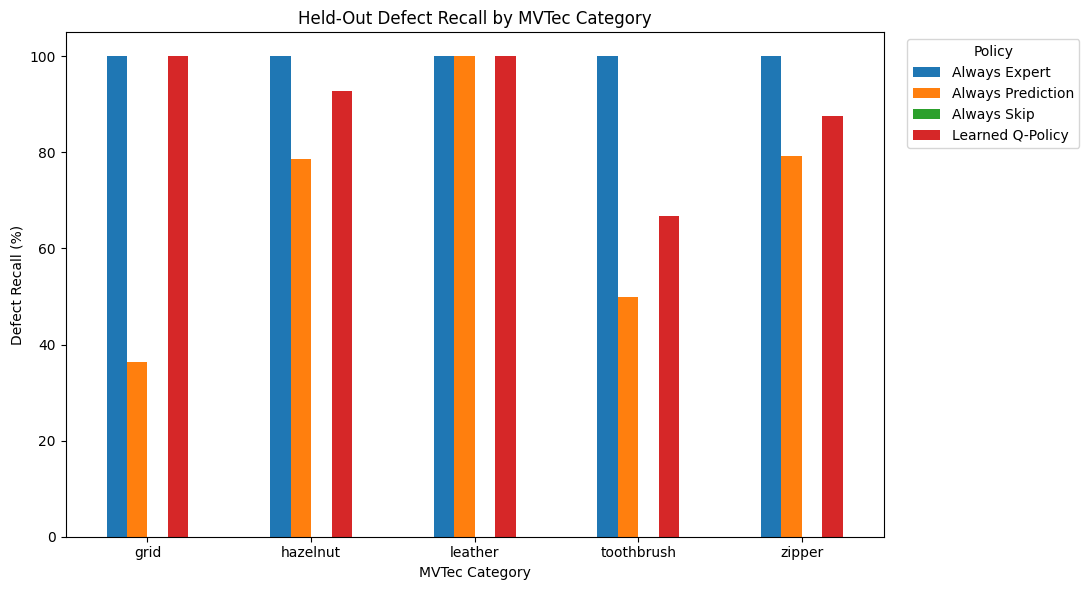

In [67]:

import matplotlib.pyplot as plt

# Prepare defect recall data for plotting
recall_plot_df = category_metrics_df.pivot(
    index="category",
    columns="policy",
    values="defect_recall"
)

ax = (recall_plot_df * 100).plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Held-Out Defect Recall by MVTec Category")
ax.set_xlabel("MVTec Category")
ax.set_ylabel("Defect Recall (%)")
ax.set_ylim(0, 105)
ax.legend(title="Policy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 10. Reward and Cost Sensitivity Analysis

### 10.1 Define Alternative Cost Scenarios

The Q-learning policy depends on the action costs and penalties used by the reward function. This experiment compares balanced, safety-focused, and cost-focused settings.

Each scenario trains a fresh Q-table using the training subset only. Policy behavior is assessed on the training subset for sensitivity analysis; these results are not independent test performance. The held-out test subset remains untouched.


In [68]:

# Define alternative reward and cost scenarios
SENSITIVITY_SCENARIOS = {
    "Balanced": {
        "skip_cost": 0,
        "prediction_cost": 1,
        "expert_cost": 5,
        "missed_defect_penalty": 10,
        "false_rejection_penalty": 3
    },

    "Safety-Focused": {
        "skip_cost": 0,
        "prediction_cost": 1,
        "expert_cost": 5,
        "missed_defect_penalty": 20,
        "false_rejection_penalty": 3
    },

    "Cost-Focused": {
        "skip_cost": 0,
        "prediction_cost": 1,
        "expert_cost": 4,
        "missed_defect_penalty": 6,
        "false_rejection_penalty": 2
    }
}

print("Sensitivity scenarios:")
display(pd.DataFrame(SENSITIVITY_SCENARIOS).T)


Sensitivity scenarios:


,skip_cost,prediction_cost,expert_cost,missed_defect_penalty,false_rejection_penalty
Balanced,0,1,5,10,3
Safety-Focused,0,1,5,20,3
Cost-Focused,0,1,4,6,2



### 10.2 Train and Compare Policies Under Different Scenarios

For each scenario, the action costs and penalties are updated, a new Q-table is initialized, and the agent is trained on the training subset. The greedy policy is then evaluated on that same training subset to show how the reward assumptions influence action selection.

The original configuration is restored after the experiment.


In [69]:

# Save the original configuration so it can be restored
original_action_costs = ACTION_COSTS.copy()
original_missed_penalty = MISSED_DEFECT_PENALTY
original_false_penalty = FALSE_REJECTION_PENALTY

sensitivity_results = []
sensitivity_q_tables = {}

try:
    for scenario_name, settings in SENSITIVITY_SCENARIOS.items():

        print(f"\nRunning scenario: {scenario_name}")

        # Apply this scenario's illustrative costs and penalties
        ACTION_COSTS = {
            "skip": settings["skip_cost"],
            "prediction": settings["prediction_cost"],
            "expert": settings["expert_cost"]
        }

        MISSED_DEFECT_PENALTY = settings["missed_defect_penalty"]
        FALSE_REJECTION_PENALTY = settings["false_rejection_penalty"]

        # Start with a fresh Q-table for this scenario
        Q_TABLE = np.zeros((len(STATES), len(ACTIONS)))

        # Train using training records only
        for episode in range(HOLDOUT_EPISODES):

            epsilon = max(
                HOLDOUT_MIN_EPSILON,
                HOLDOUT_EPSILON
                * (HOLDOUT_EPSILON_DECAY ** episode)
            )

            episode_data = train_df.sample(
                frac=1,
                random_state=SEED + episode
            )

            for _, row in episode_data.iterrows():
                state = row["state"]

                action = choose_action(
                    state,
                    epsilon=epsilon
                )

                reward = calculate_reward(row, action)

                update_q_value(
                    state=state,
                    action=action,
                    reward=reward,
                    next_state=None
                )

        # Save a copy of this scenario's learned Q-table
        sensitivity_q_tables[scenario_name] = Q_TABLE.copy()

        # Evaluate the greedy policy on training data only
        def scenario_greedy_policy(row):
            state_index = STATE_TO_INDEX[row["state"]]
            action_index = int(np.argmax(Q_TABLE[state_index]))
            return INDEX_TO_ACTION[action_index]

        scenario_results, scenario_metrics = evaluate_policy(
            train_df,
            scenario_greedy_policy
        )

        sensitivity_results.append({
            "scenario": scenario_name,
            "defect_recall": scenario_metrics["defect_recall"],
            "missed_defect_rate": scenario_metrics["missed_defect_rate"],
            "false_rejection_rate": scenario_metrics["false_rejection_rate"],
            "expert_review_rate": scenario_metrics["expert_review_rate"],
            "average_simulated_cost": scenario_metrics["average_simulated_cost"],
            "total_simulated_cost": scenario_metrics["total_simulated_cost"]
        })

finally:
    # Restore the original settings after all scenarios
    ACTION_COSTS = original_action_costs
    MISSED_DEFECT_PENALTY = original_missed_penalty
    FALSE_REJECTION_PENALTY = original_false_penalty

sensitivity_df = pd.DataFrame(sensitivity_results)

# Display rates as percentages
sensitivity_display = sensitivity_df.copy()

for column in [
    "defect_recall",
    "missed_defect_rate",
    "false_rejection_rate",
    "expert_review_rate"
]:
    sensitivity_display[column] = (
        sensitivity_display[column] * 100
    ).round(2)

sensitivity_display["average_simulated_cost"] = (
    sensitivity_display["average_simulated_cost"].round(3)
)

print("\nSensitivity analysis results (training subset only):")
display(sensitivity_display)

print("\nOriginal reward configuration restored:")
print("Action costs:", ACTION_COSTS)
print("Missed-defect penalty:", MISSED_DEFECT_PENALTY)
print("False-rejection penalty:", FALSE_REJECTION_PENALTY)



Running scenario: Balanced

Running scenario: Safety-Focused

Running scenario: Cost-Focused

Sensitivity analysis results (training subset only):


,scenario,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,total_simulated_cost
0,Balanced,95.92,4.08,15.45,18.56,1.988,803
1,Safety-Focused,99.32,0.68,15.45,30.20,2.344,947
2,Cost-Focused,95.92,4.08,15.45,18.56,1.614,652



Original reward configuration restored:
Action costs: {'skip': 0, 'prediction': 1, 'expert': 5}
Missed-defect penalty: 10
False-rejection penalty: 3


## 11. Category-Specific RL Scheduler: Motivation and Objectives

### 11.1 Motivation

The current RL-based inspection scheduler uses a shared Q-table to make inspection decisions for all five MVTec categories: grid, hazelnut, leather, toothbrush, and zipper. Although the state representation includes both product category and anomaly risk level, a shared policy may not always capture category-specific differences in inspection requirements effectively.

The held-out evaluation showed variations in defect-detection performance across categories. For example, the learned policy achieved 100% defect recall for grid and leather, 92.86% for hazelnut, 87.50% for zipper, and 66.67% for toothbrush. These differences motivate us to investigate whether training a separate scheduler for each category can improve inspection decisions.

### 11.2 Reasons for Testing Category-Specific Scheduling

1. **Differences in category performance:** The shared scheduler produced different defect-recall rates across product categories. Separate schedulers may help address these differences.

2. **Category-specific inspection requirements:** Different product categories may exhibit different anomaly-score patterns and inspection needs. Independent policies can learn action preferences using data from their respective categories.

3. **Improved defect detection:** We want to investigate whether category-specific policies can reduce missed defects, particularly in categories where the shared scheduler performed less effectively.

4. **More targeted inspection decisions:** Separate schedulers may learn different preferences for skipping further inspection, using the existing Mahalanobis prediction, or requesting expert review for each category.

5. **Performance and cost comparison:** We will compare category-specific schedulers with the existing shared scheduler using defect recall, missed-defect rate, false-rejection rate, expert-review rate, and average simulated inspection cost.

### 11.3 Objectives

- Develop five independent Q-learning schedulers, one for each MVTec category.
- Train each scheduler using only the training records belonging to its category.
- Evaluate the learned policies on the same held-out test records used for the shared-scheduler baseline.
- Compare category-level and overall performance using consistent metrics and reward assumptions.
- Determine whether category-specific scheduling provides a meaningful improvement over the shared policy.

### 11.4 Experimental Approach

The existing shared Q-learning scheduler will remain the baseline. Each category-specific scheduler will use the same three inspection actions, reward function, and learning framework, while maintaining its own Q-table.

The training and held-out test split will remain unchanged. The test records will not be used to train or tune the category-specific policies. Results will be compared on the same held-out images to ensure a fair comparison.

### 11.5 Expected Outcome

We expect this experiment to reveal whether independent category-level policies can better balance defect detection and simulated inspection cost. However, improved performance is not guaranteed. The category-specific approach will be considered beneficial only if the held-out results demonstrate a meaningful improvement without unacceptable increases in missed defects or inspection cost.

The experiment will also account for the limited number of images in some categories, which may make independently trained policies less stable.

In [70]:

# Step 11.2: Initialize category-specific Q-tables

# Each category has 3 risk levels and 3 possible actions.
RISK_LEVELS = ["low", "medium", "high"]

category_q_tables = {
    category: np.zeros((len(RISK_LEVELS), len(ACTIONS)))
    for category in sorted(train_df["category"].unique())
}

print("Number of category-specific schedulers:",
      len(category_q_tables))

for category, q_table in category_q_tables.items():
    print(f"{category}: Q-table shape = {q_table.shape}")

# Verify that all expected categories have a separate Q-table.
expected_categories = {
    "grid", "hazelnut", "leather", "toothbrush", "zipper"
}

assert set(category_q_tables.keys()) == expected_categories
assert all(
    q_table.shape == (3, 3)
    for q_table in category_q_tables.values()
)

print("\nAll five Q-tables initialized successfully.")


Number of category-specific schedulers: 5
grid: Q-table shape = (3, 3)
hazelnut: Q-table shape = (3, 3)
leather: Q-table shape = (3, 3)
toothbrush: Q-table shape = (3, 3)
zipper: Q-table shape = (3, 3)

All five Q-tables initialized successfully.


In [71]:
# Preserve the trained shared Q-table before category-specific training
shared_q_table_backup = Q_TABLE.copy()
print("Shared Q-table backup created:", shared_q_table_backup.shape)

Shared Q-table backup created: (15, 3)


In [72]:

# Step 11.3 Fix: Map risk levels to category-specific Q-table rows

RISK_TO_INDEX = {
    "low": 0,
    "medium": 1,
    "high": 2
}

def choose_category_action(state, q_table, epsilon=0.0):
    """
    Select an action using the category-specific Q-table.
    State format: (category, risk_level).
    """
    risk_level = state[1]
    state_index = RISK_TO_INDEX[risk_level]

    # Explore: select a random action
    if np.random.random() < epsilon:
        action_index = np.random.randint(len(ACTIONS))
    else:
        # Exploit: select the action with the highest Q-value
        q_values = q_table[state_index]
        best_actions = np.flatnonzero(
            q_values == q_values.max()
        )
        action_index = np.random.choice(best_actions)

    return INDEX_TO_ACTION[action_index]

print("Category-specific action selection is ready.")


# Step 11.3 Fix: Q-learning update for category-specific tables

def update_category_q_value(
    state, action, reward, q_table, next_state=None
):
    """
    Update a category-specific Q-table.
    Each image is an independent terminal decision.
    """
    risk_level = state[1]
    state_index = RISK_TO_INDEX[risk_level]
    action_index = ACTION_TO_INDEX[action]

    current_q = q_table[state_index, action_index]

    # Terminal decision: no future reward
    next_max_q = 0.0

    target = reward + GAMMA * next_max_q

    q_table[state_index, action_index] = (
        current_q + ALPHA * (target - current_q)
    )

    return q_table[state_index, action_index]


print("Category-specific Q-value update function is ready.")



Category-specific action selection is ready.
Category-specific Q-value update function is ready.


### 11.3 Train the Category-Specific Schedulers

Each category-specific scheduler is trained independently using only the training records belonging to its product category. During training, the agent observes the risk level, selects an inspection action using an epsilon-greedy strategy, and updates the corresponding Q-value using the existing reward function.

A separate Q-table is maintained for each category. The learning rate, discount factor, exploration schedule, action costs, and reward penalties remain consistent with the shared-scheduler experiment.

The held-out test set is not used during training. This ensures that the category-specific policies can be compared fairly against the shared scheduler using the same test records.

In [73]:

# Step 11.3: Train each category-specific scheduler

category_training_rewards = {}

for category in sorted(category_q_tables.keys()):

    print(f"\nTraining scheduler for: {category}")

    # Select only this category's training records
    category_train = train_df[
        train_df["category"] == category
    ].copy()

    assert len(category_train) > 0, (
        f"No training records found for {category}"
    )

    # Start with the category's independent Q-table
    Q_TABLE = category_q_tables[category]

    episode_rewards = []

    for episode in range(HOLDOUT_EPISODES):

        epsilon = max(
            HOLDOUT_MIN_EPSILON,
            HOLDOUT_EPSILON
            * (HOLDOUT_EPSILON_DECAY ** episode)
        )

        # Shuffle only this category's training records
        episode_data = category_train.sample(
            frac=1,
            random_state=SEED + episode
        )

        total_reward = 0

        for _, row in episode_data.iterrows():

            state = row["state"]

            # Select an action using the existing epsilon-greedy function
            action = choose_category_action(
               state,
               Q_TABLE,
               epsilon=epsilon
            )

            # Calculate reward using the existing reward function
            reward = calculate_reward(row, action)

            # Each image is an independent terminal decision
            update_category_q_value(
                state=state,
                action=action,
                reward=reward,
                q_table=Q_TABLE,
                next_state=None
            )

            total_reward += reward

        episode_rewards.append(total_reward)

    # Save the trained Q-table and rewards for this category
    category_q_tables[category] = Q_TABLE.copy()
    category_training_rewards[category] = episode_rewards

    print("Training records:", len(category_train))
    print("Final episode reward:", episode_rewards[-1])
    print("Q-table shape:", category_q_tables[category].shape)

# Restore the shared Q-table from the held-out experiment
# so subsequent shared-policy evaluation remains unchanged.
Q_TABLE = q_table_df.values.copy() if "q_table_df" in globals() else Q_TABLE

print("\nAll category-specific schedulers trained.")



Training scheduler for: grid
Training records: 63
Final episode reward: -300
Q-table shape: (3, 3)

Training scheduler for: hazelnut
Training records: 88
Final episode reward: -125
Q-table shape: (3, 3)

Training scheduler for: leather
Training records: 99
Final episode reward: -161
Q-table shape: (3, 3)

Training scheduler for: toothbrush
Training records: 33
Final episode reward: -46
Q-table shape: (3, 3)

Training scheduler for: zipper
Training records: 121
Final episode reward: -224
Q-table shape: (3, 3)

All category-specific schedulers trained.


### 11.4 Evaluate Category-Specific Schedulers on Held-Out Data

After training, each category-specific scheduler is evaluated using only the held-out test records belonging to its respective category. The policies are not retrained during evaluation.

The results are compared with the existing shared Q-learning scheduler and the three baseline policies. We measure defect recall, missed-defect rate, false-rejection rate, expert-review rate, and average simulated inspection cost.

This comparison will determine whether category-specific learning improves inspection performance or cost efficiency. Since the test subsets are relatively small, the results will be interpreted cautiously.

In [74]:

# Step 11.4: Evaluate category-specific schedulers on held-out data

category_policy_results = {}
category_comparison_rows = []

# Preserve the shared policy's Q-table
shared_q_table_backup = Q_TABLE.copy()

try:
    for category in sorted(category_q_tables.keys()):

        print(f"Evaluating category: {category}")

        # Select only held-out records from this category
        category_test = test_df[
            test_df["category"] == category
        ].copy()

        assert len(category_test) > 0, (
            f"No test records found for {category}"
        )

        # Load this category's independently trained Q-table
        category_q_table = category_q_tables[category]

        def category_policy(row, q_table=category_q_table):
            return choose_category_action(
                row["state"],
                q_table,
                epsilon=0.0
            )

        # Evaluate without any Q-table updates
        results_df, metrics = evaluate_policy(
            category_test,
            category_policy
        )

        category_policy_results[category] = results_df

        category_comparison_rows.append({
            "category": category,
            "test_images": len(category_test),
            **metrics
        })

finally:
    # Keep the shared scheduler unchanged
    Q_TABLE = shared_q_table_backup.copy()

# Display category-specific evaluation
category_comparison_df = pd.DataFrame(
    category_comparison_rows
)

category_display = category_comparison_df.copy()

for column in [
    "defect_recall",
    "missed_defect_rate",
    "false_rejection_rate",
    "expert_review_rate"
]:
    category_display[column] = (
        category_display[column] * 100
    ).round(2)

category_display["average_simulated_cost"] = (
    category_display["average_simulated_cost"].round(3)
)

print("\nCategory-specific scheduler results (held-out data):")
display(category_display)

# Verify traceability
for category, results_df in category_policy_results.items():
    expected_paths = set(
        test_df.loc[
            test_df["category"] == category,
            "image_path"
        ]
    )

    assert set(results_df["image_path"]) == expected_paths
    assert results_df["image_path"].notna().all()

print("\nHeld-out evaluation and image-path checks passed.")


Evaluating category: grid
Evaluating category: hazelnut
Evaluating category: leather
Evaluating category: toothbrush
Evaluating category: zipper

Category-specific scheduler results (held-out data):


,category,test_images,defect_recall,missed_defect_rate,false_rejection_rate,expert_review_rate,average_simulated_cost,total_simulated_cost,missed_defect_count,false_rejection_count
0,grid,15,100.00,0.00,25.0,66.67,3.867,58,0,1
1,hazelnut,22,92.86,7.14,0.0,13.64,1.636,36,1,0
2,leather,25,100.00,0.00,50.0,0.00,1.240,31,0,3
3,toothbrush,9,66.67,33.33,0.0,11.11,3.111,28,2,0
4,zipper,30,87.50,12.50,0.0,6.67,1.967,59,3,0



Held-out evaluation and image-path checks passed.


### 11.5 Compare Shared and Category-Specific Policies

This section compares the action selected by the shared scheduler with the action selected by each category-specific scheduler for every held-out image.

Although the two approaches use different Q-table structures, they may learn identical or different action preferences. Comparing their decisions will help determine whether category-specific training changes the inspection policy and whether any performance differences are attributable to those changes.

The comparison will also verify that the shared Q-table remains unchanged after the category-specific experiment.

In [75]:
# Step 11.5: Compare shared and category-specific actions by image_path

# Shared scheduler results on the held-out test set
shared_results = holdout_policy_results["Learned Q-Policy"].copy()

# Combine category-specific results without overwriting the original dictionary
category_results_df = pd.concat(
    list(category_policy_results.values()),
    ignore_index=True
)

# Align both policies by image identity before comparing actions
decision_comparison = shared_results[
    ["image_path", "category", "risk_level", "label", "selected_action"]
].merge(
    category_results_df[["image_path", "selected_action"]],
    on="image_path",
    how="inner",
    validate="one_to_one",
    suffixes=("_shared", "_category")
)

assert len(decision_comparison) == len(test_df), (
    "Not all held-out images were matched between the schedulers."
)

decision_comparison["actions_match"] = (
    decision_comparison["selected_action_shared"]
    == decision_comparison["selected_action_category"]
)

print("Matched held-out images:", len(decision_comparison))
print(
    "Action agreement after image_path alignment:",
    f"{decision_comparison['actions_match'].mean() * 100:.2f}%"
)

print("\nAction agreement by category:")
display(
    decision_comparison.groupby("category")["actions_match"]
    .agg(["count", "mean"])
    .assign(
        agreement_percent=lambda x: (x["mean"] * 100).round(2)
    )
    .drop(columns="mean")
)

print("\nShared vs category-specific action counts:")
display(pd.crosstab(
    decision_comparison["selected_action_shared"],
    decision_comparison["selected_action_category"],
    rownames=["Shared action"],
    colnames=["Category-specific action"]
))


Matched held-out images: 101
Action agreement after image_path alignment: 100.00%

Action agreement by category:


,count,agreement_percent
category,,
grid,15,100.0
hazelnut,22,100.0
leather,25,100.0
toothbrush,9,100.0
zipper,30,100.0



Shared vs category-specific action counts:


Category-specific action,expert,prediction,skip
Shared action,,,
expert,16,0,0
prediction,0,60,0
skip,0,0,25


### 11.6 Interpretation of the Aligned Policy Comparison

The initial row-by-row comparison was not reliable because the two result tables were not guaranteed to have the same row order. The comparison is now aligned using `image_path`, which uniquely identifies each held-out image.

After alignment, the shared and category-specific schedulers selected the same action for **all 101 held-out images (100% action agreement)**. There are therefore no genuine zipper-only action disagreements to investigate in this run.

The category-specific experiment does not improve the measured held-out results in this experiment. The shared scheduler remains the primary implementation because it is simpler and produces identical decisions on the evaluated images.


### 11.7 Interpretation of Category-Specific Scheduling Results

The category-specific scheduling experiment tested whether separate Q-tables for grid, hazelnut, leather, toothbrush, and zipper would change the learned inspection actions.

**Key findings:**
- The shared and category-specific schedulers were compared on the same 101 held-out images, aligned by `image_path`.
- Action agreement was **100%**.
- Both approaches achieved the same defect recall (91.89%), missed-defect rate (8.11%), false-rejection rate (14.81%), expert-review rate (15.84%), and total simulated cost (212).
- No improvement from category-specific scheduling was demonstrated on this held-out split.

The shared scheduler is retained as the primary approach because it gives the same observed decisions with a simpler implementation. Costs are illustrative, expert review is assumed perfect in simulation, and these results are not production guarantees.


## 11.7 Overall Comparison: Shared vs Category-Specific Schedulers

This experiment compares the shared Q-learning scheduler with five category-specific schedulers using the same held-out test images.

The shared scheduler uses one Q-table across all product categories, whereas the category-specific approach uses a separate Q-table for grid, hazelnut, leather, toothbrush, and zipper.

Both approaches will be evaluated using defect recall, missed-defect rate, false-rejection rate, expert-review rate, and average and total simulated cost. The comparison will also verify that every held-out image is evaluated by both approaches.

The purpose is to determine whether category-specific policies provide a measurable benefit over the shared policy. Since the test set contains only 101 images, the results will be treated as an experimental comparison rather than proof of general superiority.

In [76]:
# Inspect the category-specific results dictionary
print("Object type:", type(category_policy_results))
print("Keys:", list(category_policy_results.keys()))

for key, value in category_policy_results.items():
    print(f"\nKey: {key}")
    print("Value type:", type(value))

    if isinstance(value, pd.DataFrame):
        print("Columns:", value.columns.tolist())
        print("Number of rows:", len(value))
    elif isinstance(value, dict):
        print("Nested keys:", list(value.keys()))

Object type: <class 'dict'>
Keys: ['grid', 'hazelnut', 'leather', 'toothbrush', 'zipper']

Key: grid
Value type: <class 'pandas.core.frame.DataFrame'>
Columns: ['image_path', 'category', 'risk_level', 'state', 'label', 'mahalanobis_prediction', 'selected_action', 'final_decision', 'missed_defect', 'false_rejection', 'reward', 'simulated_cost']
Number of rows: 15

Key: hazelnut
Value type: <class 'pandas.core.frame.DataFrame'>
Columns: ['image_path', 'category', 'risk_level', 'state', 'label', 'mahalanobis_prediction', 'selected_action', 'final_decision', 'missed_defect', 'false_rejection', 'reward', 'simulated_cost']
Number of rows: 22

Key: leather
Value type: <class 'pandas.core.frame.DataFrame'>
Columns: ['image_path', 'category', 'risk_level', 'state', 'label', 'mahalanobis_prediction', 'selected_action', 'final_decision', 'missed_defect', 'false_rejection', 'reward', 'simulated_cost']
Number of rows: 25

Key: toothbrush
Value type: <class 'pandas.core.frame.DataFrame'>
Columns: ['

In [77]:
# Step 11.7: Overall comparison of shared and category-specific schedulers

# Reconstruct category_results_df directly from the correct dictionary to ensure it exists
category_results_df = pd.concat(
    list(category_policy_results.values()),
    ignore_index=True
)

# Extract the shared scheduler's held-out decisions
shared_results = holdout_policy_results["Learned Q-Policy"].copy()

# Verify that both schedulers evaluated the same images
assert len(shared_results) == len(test_df), \
    "Shared scheduler result count does not match the test set."

assert len(category_results_df) == len(test_df), \
    "Category-specific result count does not match the test set."

assert set(shared_results["image_path"]) == set(category_results_df["image_path"]), \
    "The two schedulers were not evaluated on the same images."

# Calculate overall evaluation metrics
def calculate_overall_metrics(results):
    total_defects = int((results["label"] == 1).sum())
    total_good = int((results["label"] == 0).sum())

    missed = int(results["missed_defect"].sum())
    false_rejections = int(results["false_rejection"].sum())

    return {
        "defect_recall (%)": round(
            100 * (total_defects - missed) / total_defects, 2
        ) if total_defects else 0,

        "missed_defect_rate (%)": round(
            100 * missed / total_defects, 2
        ) if total_defects else 0,

        "false_rejection_rate (%)": round(
            100 * false_rejections / total_good, 2
        ) if total_good else 0,

        "expert_review_rate (%)": round(
            100 * (results["selected_action"] == "expert").mean(), 2
        ),

        "average_simulated_cost": round(
            results["simulated_cost"].mean(), 3
        ),

        "total_simulated_cost": int(results["simulated_cost"].sum()),

        "missed_defects": missed,

        "false_rejections": false_rejections
    }


# Create the comparison table
overall_scheduler_comparison = pd.DataFrame([
    {
        "scheduler": "Shared Q-Policy",
        **calculate_overall_metrics(shared_results)
    },
    {
        "scheduler": "Category-Specific Q-Policies",
        **calculate_overall_metrics(category_results_df)
    }
])

print("Overall comparison on identical held-out images")
print("Number of test images:", len(shared_results))
display(overall_scheduler_comparison)

print("\nImage-path verification passed.")

Overall comparison on identical held-out images
Number of test images: 101


,scheduler,defect_recall (%),missed_defect_rate (%),false_rejection_rate (%),expert_review_rate (%),average_simulated_cost,total_simulated_cost,missed_defects,false_rejections
0,Shared Q-Policy,91.89,8.11,14.81,15.84,2.099,212,6,4
1,Category-Specific Q-Policies,91.89,8.11,14.81,15.84,2.099,212,6,4



Image-path verification passed.


In [78]:
# Final verification: confirm category-specific Q-tables and aligned policy agreement

print("Category-specific Q-table verification")
for category in CATEGORIES:
    q_table = category_q_tables[category]
    print(
        f"{category}: shape={q_table.shape}, "
        f"trained={bool(np.any(q_table != 0))}"
    )

aligned_actions = shared_results[
    ["image_path", "selected_action"]
].merge(
    category_results_df[["image_path", "selected_action"]],
    on="image_path",
    how="inner",
    validate="one_to_one",
    suffixes=("_shared", "_category")
)

assert len(aligned_actions) == len(test_df)
agreement = (
    aligned_actions["selected_action_shared"]
    == aligned_actions["selected_action_category"]
).mean() * 100

print(f"\nAligned action agreement: {agreement:.2f}%")


Category-specific Q-table verification
grid: shape=(3, 3), trained=True
zipper: shape=(3, 3), trained=True
hazelnut: shape=(3, 3), trained=True
leather: shape=(3, 3), trained=True
toothbrush: shape=(3, 3), trained=True

Aligned action agreement: 100.00%


In [79]:
# Final action-agreement check, aligned by image_path

aligned = shared_results[
    ["image_path", "selected_action"]
].merge(
    category_results_df[["image_path", "selected_action"]],
    on="image_path",
    how="inner",
    validate="one_to_one",
    suffixes=("_shared", "_category")
)

assert len(aligned) == len(test_df)
agreement = (
    aligned["selected_action_shared"]
    == aligned["selected_action_category"]
).mean() * 100

print("Matched images:", len(aligned))
print(f"Action agreement after alignment: {agreement:.2f}%")
assert agreement == 100.0, "Unexpected difference in aligned policy actions."


Matched images: 101
Action agreement after alignment: 100.00%


## 12. Final Conclusion and Project Status

### 12.1 Conclusion

The Adaptive Visual Inspection System uses a Q-learning-based scheduler to select an inspection action for each product based on its category and anomaly risk level. The available actions are Skip, Prediction, and Expert Review.

The shared Q-learning scheduler was evaluated on 101 held-out images and achieved a defect recall of **91.89%**, a missed-defect rate of **8.11%**, a false-rejection rate of **14.81%**, and an average simulated cost of **2.099 units per image**. It missed 6 defective products, falsely rejected 4 good products, and selected expert review for 15.84% of the test images.

Five category-specific Q-tables were also trained for grid, hazelnut, leather, toothbrush, and zipper. After aligning both schedulers' outputs using `image_path`, the action agreement was **100% across all 101 held-out images**. Therefore, the category-specific approach did not change the selected actions or improve the measured outcomes in this experiment.

The shared scheduler is consequently retained as the primary approach because it achieves the same observed decisions with a simpler implementation. Category-specific schedulers remain a useful extension to investigate if future data or a revised state representation reveals meaningful category-level differences.

### 12.2 Limitations

- The evaluation uses a single held-out split of a relatively small dataset.
- Inspection costs and penalties are illustrative simulation settings, not measured industrial costs.
- Expert review is assumed to be perfect in the simulation.
- The anomaly scores are generated by a fixed Mahalanobis vision model. The upstream vision-model selection used test-set AUC, so the overall system evaluation is not a completely independent end-to-end assessment.
- Each image is treated as an independent terminal decision. Thus, the current method is closer to a contextual-bandit or immediate action-value learning setup than a sequential inspection process with long-term state transitions.

### 12.3 Final Status

The shared scheduler, held-out evaluation, per-category analysis, reward/cost sensitivity analysis, and category-specific scheduler experiment have been implemented. Image-path traceability is preserved, and the final scheduler comparison has been aligned and verified.

The results support the shared scheduler as the simpler current choice. Further claims about industrial readiness or generalization require additional independent data and realistic cost measurements.

### 13. Export Reusable Scheduler Outputs

The notebook exports two separate CSV files and a metadata JSON file:

- `scheduler_inference_ready.csv`: operational fields for RAG, dashboards, or downstream integration. It excludes ground-truth labels and evaluation error fields.
- `scheduler_evaluation.csv`: held-out evaluation fields, including labels, missed defects, false rejections, and simulated cost, for audit and reporting.
- `scheduler_metadata.json`: describes the model, scheduler, held-out scope, and evaluation limitations.

Both CSV files preserve `image_path` for traceability. These files currently contain the 101 held-out test images, not all 505 dataset images.

In [80]:
# Step 13.1: Export held-out evaluation results and metadata

from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("scheduler_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Evaluation-only file: retain ground truth and error/cost fields for audit
evaluation_columns = [
    "image_path",
    "category",
    "risk_level",
    "label",
    "selected_action",
    "final_decision",
    "missed_defect",
    "false_rejection",
    "simulated_cost",
]
evaluation_columns = [
    col for col in evaluation_columns if col in shared_results.columns
]
evaluation_output = shared_results[evaluation_columns].copy()

assert evaluation_output["image_path"].notna().all()
assert evaluation_output["image_path"].is_unique
assert len(evaluation_output) == len(test_df)

evaluation_path = OUTPUT_DIR / "scheduler_evaluation.csv"
evaluation_output.to_csv(evaluation_path, index=False)

metadata = {
    "project": "Adaptive Visual Inspection System",
    "primary_scheduler": "Shared Q-learning",
    "vision_model": "Mahalanobis",
    "actions": ["skip", "prediction", "expert"],
    "risk_levels": ["low", "medium", "high"],
    "evaluation_split": "held-out test set",
    "record_count": int(len(evaluation_output)),
    "image_path_preserved": bool(evaluation_output["image_path"].notna().all()),
    "unique_image_paths": bool(evaluation_output["image_path"].is_unique),
    "evaluation_note": (
        "This file contains held-out evaluation records only. "
        "Costs are simulated and expert review is assumed perfect. "
        "The upstream vision-model selection used test-set AUC, so "
        "the end-to-end evaluation is not fully independent."
    ),
    "outputs": {
        "inference": "scheduler_inference_ready.csv",
        "evaluation": "scheduler_evaluation.csv"
    }
}

metadata_path = OUTPUT_DIR / "scheduler_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Evaluation output and metadata saved.")
print("Evaluation records:", len(evaluation_output))
print("Unique image paths:", evaluation_output["image_path"].nunique())
print("Evaluation CSV:", evaluation_path)
print("Metadata JSON:", metadata_path)
display(evaluation_output.head())


Evaluation output and metadata saved.
Evaluation records: 101
Unique image paths: 101
Evaluation CSV: scheduler_outputs/scheduler_evaluation.csv
Metadata JSON: scheduler_outputs/scheduler_metadata.json


,image_path,category,risk_level,label,selected_action,final_decision,missed_defect,false_rejection,simulated_cost
0,leather/test/color/010.png,leather,high,1,prediction,1,0,0,1
1,zipper/test/good/013.png,zipper,low,0,skip,0,0,0,0
2,hazelnut/test/cut/007.png,hazelnut,high,1,prediction,1,0,0,1
3,zipper/test/combined/005.png,zipper,high,1,prediction,1,0,0,1
4,hazelnut/test/print/008.png,hazelnut,high,1,prediction,1,0,0,1


In [81]:
# Step 13.2: Export inference-ready decisions for downstream integration

# Keep operational decision fields only; do not export ground-truth labels or evaluation errors.
inference_columns = [
    "image_path",
    "category",
    "risk_level",
    "selected_action",
    "mahalanobis_prediction",
]
inference_columns = [
    col for col in inference_columns if col in shared_results.columns
]
inference_output = shared_results[inference_columns].copy()

next_steps = {
    "skip": "No additional inspection selected by the scheduler",
    "prediction": "Use the Mahalanobis model prediction",
    "expert": "Route image to an expert for review",
}
decision_status = {
    "skip": "No additional inspection selected",
    "prediction": "Use model prediction",
    "expert": "Pending expert review",
}

inference_output["recommended_next_step"] = (
    inference_output["selected_action"].map(next_steps)
)
inference_output["final_decision_status"] = (
    inference_output["selected_action"].map(decision_status)
)

# Validate output integrity
assert inference_output["image_path"].notna().all()
assert inference_output["image_path"].is_unique
assert len(inference_output) == len(test_df)
assert inference_output["recommended_next_step"].notna().all()
assert not any(
    col in inference_output.columns
    for col in ["label", "missed_defect", "false_rejection", "reward", "simulated_cost"]
)

inference_path = OUTPUT_DIR / "scheduler_inference_ready.csv"
inference_output.to_csv(inference_path, index=False)

print("Inference-ready output saved successfully.")
print("Records:", len(inference_output))
print("Unique image paths:", inference_output["image_path"].nunique())
print("Columns:", inference_output.columns.tolist())
print("CSV:", inference_path)
display(inference_output.head())


Inference-ready output saved successfully.
Records: 101
Unique image paths: 101
Columns: ['image_path', 'category', 'risk_level', 'selected_action', 'mahalanobis_prediction', 'recommended_next_step', 'final_decision_status']
CSV: scheduler_outputs/scheduler_inference_ready.csv


,image_path,category,risk_level,selected_action,mahalanobis_prediction,recommended_next_step,final_decision_status
0,leather/test/color/010.png,leather,high,prediction,1,Use the Mahalanobis model prediction,Use model prediction
1,zipper/test/good/013.png,zipper,low,skip,0,No additional inspection selected by the sched...,No additional inspection selected
2,hazelnut/test/cut/007.png,hazelnut,high,prediction,1,Use the Mahalanobis model prediction,Use model prediction
3,zipper/test/combined/005.png,zipper,high,prediction,1,Use the Mahalanobis model prediction,Use model prediction
4,hazelnut/test/print/008.png,hazelnut,high,prediction,1,Use the Mahalanobis model prediction,Use model prediction
